# Computations for Figures 4 and 5

Compute the tangent-plane correction across an observer grid and its temporal variation for a selected observer during the Io occultation on April 2, 2021.

This notebook accompanies the article; equation, table and figure numbers refer
to that text. It is intended to reproduce the numerical example, so derivations
and applicability conditions are not repeated here.

**Before running:** place `light_deflection.py` and `ephemeris.py` in the notebook
directory (using these exact module names). Install NumPy, Astropy, SpiceyPy and
Jupyter; the figure notebook additionally imports Matplotlib, SciPy and tqdm.
Set `kernel` below to your local SPK path(s); the supplied absolute path is
specific to the original server. The loaded kernels must cover Earth and all
requested targets relative to the Solar System barycenter. Run cells in order
after restarting the kernel. The calls to `spice.kclear()` clear all kernels
loaded in the current process.

The stellar coordinate below is a fixed, previously propagated input; its
preparation is not rerun here. `ephem_kernel` converts reception times to TDB
and iterates geometric light time independently for each target. See its
docstring for frame, epoch, observer and returned-velocity conventions.


## Initial imports and parameters

In [1]:
import numpy as np
import astropy.units as u
import astropy.constants as const
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, CartesianRepresentation
import spiceypy as spice

from light_deflection import delta_kpn, calc_kP
from ephemeris import ephem_kernel, on_sky_velocity

from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic_2d

plt.rcParams['font.size'] = 12

In [2]:
# Occultation parameters from Morgado et al. (2022)
occ_time = Time('2021-04-02 10:24:00', scale='utc')
occ_vel = 16.54*u.km/u.s
io_radius = 1821*u.km

In [3]:
# Geocentric star position at occultation epoch from Morgado et al. (2022)
# The star position was propagated with proper motion, parallax and radial velocity
# using Butkevich & Lindegren (2014) with SORA.
# It is given here as a fixed coordinate.
pos_star = SkyCoord('21h43m04.38939019s -14d23m58.5335448s', distance=142.9253799674684*u.pc)

GM of Jupiter and Sun from JUP365: https://naif.jpl.nasa.gov/pub/naif/generic_kernels/spk/satellites/jup365.cmt

In [4]:
# GM of Jupiter and Sun form JUP365: https://naif.jpl.nasa.gov/pub/naif/generic_kernels/spk/satellites/jup365.cmt
jup_GM = 1.266865319003704E+08 * (u.km**3) / (u.s**2)
sun_GM = 1.327132332633514E+11 * (u.km**3) / (u.s**2)
# NAIF target IDs for Jupiter, the Sun and Io.
jup_spkid = '599'
sun_spkid = '10'
io_spkid = '501'

## Ephemeris computation

Use `ephem_kernel` from `ephemeris.py` to compute Jupiter, Sun and Io positions
for a grid of observers at the same reception epoch. The example uses
[JUP365](https://naif.jpl.nasa.gov/pub/naif/generic_kernels/spk/satellites/jup365.bsp);
update the local kernel path below.

The grid contains 501 geodetic longitudes from -52 to -7 degrees and 501
geodetic latitudes from -21 to 25 degrees, for 251,001 locations. Height is zero
above Astropy's default reference ellipsoid, not a geoid-based sea level.
Array axis 0 is longitude and axis 1 is latitude. `EarthLocation.get_gcrs`
provides the observer states; reproducibility also depends on Astropy's
Earth-orientation data. See the helper's docstring for its frame approximation.


In [5]:
lons = np.linspace(-52,-7, 501)*u.deg
lats = np.linspace(-21, 25, 501)*u.deg

In [6]:
# Defining an Astropy EarthLocation object for a grid of these locations.
obs = EarthLocation(lon=lons[:,np.newaxis], lat=lats[np.newaxis,:], height=0*u.km)

In [7]:
# Set this path to your local JUP365 kernel before running.
kernel = ['/srv/jupyterhub/shared/data/kernels/jup365.bsp']

In [8]:
# The positions of Jupiter, the Sun and Io are computed
# for all simulated observers simultaneously
spice.furnsh(kernel)
pos_jup, vel_jup = ephem_kernel(occ_time, jup_spkid, obs)
pos_sun, vel_sun = ephem_kernel(occ_time, sun_spkid, obs)
pos_io, vel_io = ephem_kernel(occ_time, io_spkid, obs)
spice.kclear()

## Geometric tangent plane coordinates

Distance of the body to the observers
$$D_E = \|\vec{x}_E - \vec{x}_O\|$$

In [9]:
DE_io = pos_io.cartesian.norm()

Computed the geometric tangent plane coordinates (f,g), Equation (5) in the draft.

$$\vec{u} = (f,g)$$

$$f\approx D_E(\alpha_\star - \alpha_E)\cos\delta_E$$
$$g\approx D_E(\delta_\star - \delta_E)$$

In [10]:
f = DE_io*(pos_star.ra - pos_io.spherical.lon)*np.cos(pos_io.spherical.lat)
g = DE_io*(pos_star.dec - pos_io.spherical.lat)
f = f.to(u.km, equivalencies=u.dimensionless_angles())
g = g.to(u.km, equivalencies=u.dimensionless_angles())

The next cell map the observer grid to geometric tangent-plane coordinates
and plot Io as a circle of radius `io_radius`. The curved grid pattern arises
from projecting locations distributed over Earth's surface.


(-3000.0, 3000.0)

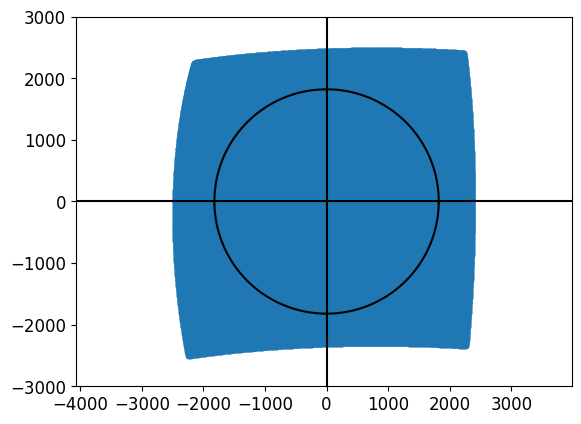

In [11]:
plt.scatter(f, g, marker='.')
plt.axhline(0.0, color='black')
plt.axvline(0.0, color='black')
ang = np.linspace(0,360,1000)*np.pi/180
plt.plot(io_radius*np.cos(ang), io_radius*np.sin(ang), color='black')
plt.axis('equal')
plt.ylim(-3000,3000)

## Event-level tangent-plane corrections

For each observer, compute the stellar deflection due to Jupiter and the Sun
separately using `delta_kpn` in `light_deflection.py` (Equation 9):

$$\delta\hat{k}_{\rm pN} = \sum_A \frac{(1+\gamma)GM_A}{c^2}
\frac{\vec{r}_{SO}\times(\vec{r}_{AO}\times\vec{r}_{AS})}
{|\vec{r}_{SO}||\vec{r}_{AO}|(|\vec{r}_{AS}||\vec{r}_{AO}|+\vec{r}_{AS}\cdot\vec{r}_{AO})}.$$

Each call evaluates one term of the sum. The point-P correction is then
computed iteratively in the following cells.


In [12]:
# Light deflection for the star
vec_rso = - pos_star.cartesian
vec_rao = - pos_jup.cartesian
vec_ras = pos_star.cartesian - pos_jup.cartesian
delta_k_star_jup = delta_kpn(gm=jup_GM, vec_rso=vec_rso, vec_rao=vec_rao, vec_ras=vec_ras)

vec_rso = - pos_star.cartesian
vec_rao = - pos_sun.cartesian
vec_ras = pos_star.cartesian - pos_sun.cartesian
delta_k_star_sun = delta_kpn(gm=sun_GM, vec_rso=vec_rso, vec_rao=vec_rao, vec_ras=vec_ras)

`calc_kP` in `light_deflection.py` iterates the correction for a finite-distance
point P, separately for each deflector. The tangent basis at E is
(Equations 2 and 3):

$$\hat{e}_f=(-\sin\alpha_E,\cos\alpha_E,0),$$
$$\hat{e}_g=(-\sin\delta_E\cos\alpha_E,-\sin\delta_E\sin\alpha_E,\cos\delta_E).$$

The intended update starts with zero corrections and keeps the geometric
coordinates $(f,g)$ fixed:

1. Form the current point (Equation 13),
   $$\vec{x}_P=\vec{x}_E+(f+\Delta f_P)\hat{e}_f+(g+\Delta g_P)\hat{e}_g.$$
2. Evaluate its deflection with Equation 9 and compute
   $\Delta\vec{\theta}_P=\delta\hat{k}_P-\delta\hat{k}_\star$ (Equation 19).
3. Update the correction (Equation 20):
   $$\Delta f_P^{\rm new}=D_E\Delta\vec{\theta}_P\cdot\hat{e}_f,\qquad
   \Delta g_P^{\rm new}=D_E\Delta\vec{\theta}_P\cdot\hat{e}_g.$$
4. Repeat until the maximum change in the correction over the input grid
   is at most 1 m. The implementation uses `np.nanmax` and recursive calls,
   without an explicit iteration limit.

In [13]:
# Light deflection for the finite-distance point P
delta_f_jup, delta_g_jup = calc_kP(gm=jup_GM, pos_A=pos_jup, pos_E=pos_io, delta_k_star = delta_k_star_jup, f=f, g=g, delta_f_P=0*u.km, delta_g_P=0*u.km)
delta_f_sun, delta_g_sun = calc_kP(gm=sun_GM, pos_A=pos_sun, pos_E=pos_io, delta_k_star = delta_k_star_sun, f=f, g=g, delta_f_P=0*u.km, delta_g_P=0*u.km)

Sum the corrections returned by the separate Jupiter and Sun calculations.


In [14]:
delta_f_P = delta_f_jup + delta_f_sun
delta_g_P = delta_g_jup + delta_g_sun

Form the corrected tangent-plane coordinates by adding each correction to
its corresponding geometric coordinate. **Implementation check:** the second
assignment below uses `f`; the g coordinate should start from `g`. These two
arrays are not used in the plots that follow.


In [15]:
f_P = f + delta_f_P
g_P = g + delta_g_P

## Figure 4a

Plot the magnitude of the combined Jupiter-plus-Sun correction as contours
over the geometric $(f,g)$ coordinates. First select the sampled observer
closest to the tangent-plane origin; `v` is its two-dimensional grid index.
This is a discrete approximation to a central observer, not necessarily an
observer whose geometric coordinates are exactly zero.

Bin the correction magnitudes into a uniform 40 by 40 grid, using the mean
within each bin. Contour labels are in km. Empty bins may contain NaN.
The figure is saved as `Light_deflection_correction.png`.


In [16]:
# Identifies the array item closest to the tangent plane origin
chord_dist = np.sqrt(f**2+g**2)
v = np.unravel_index(chord_dist.argmin(), chord_dist.shape)

In [17]:
# Since the (f,g) coordinates are not uniform over the tangent plane,
# we binned the data to obtain a uniform grid (40x40).

nx = 40
ny = 40

# Total deflection in each pixel
delta_fg = np.sqrt(delta_f_P**2 + delta_g_P**2)

# Bin delta_fg
fg_mean, xedges, yedges, _ = binned_statistic_2d(
    f.flatten(), g.flatten(), delta_fg.flatten(),
    statistic='mean',
    bins=[nx, ny]
)

# (f,g) coordinates of the binned pixels
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


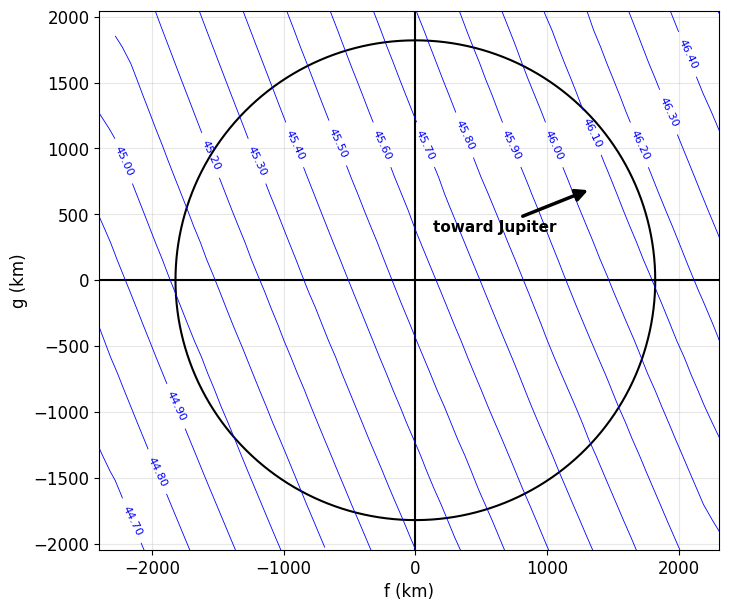

In [18]:
fig, ax = plt.subplots(figsize=(8, 7))

# Plot axis
plt.axhline(0.0, color='black')
plt.axvline(0.0, color='black')

# Plot Io circular shape
ang = np.linspace(0,360,1000)*np.pi/180
plt.plot(io_radius*np.cos(ang),io_radius*np.sin(ang), color='black')

# Contour plot of equal deflection
contour_lines = ax.contour(
    xc,
    yc,
    fg_mean.T,
    levels=20,
    linewidths=0.6,
    colors='blue'
)

# Labels of each line
ax.clabel(
    contour_lines,
    inline=True,
    fontsize=8,
    fmt='%.2f'
)

# Plot the direction of Jupiter
x_0, y_0 = 600, 400
ax.annotate(
    'toward Jupiter',
    xy=(x_0 - delta_f_jup[v].value*20, y_0 - delta_g_jup[v].value*20),          # ponta da seta
    xytext=(x_0, y_0),
    fontsize=11,
    fontweight='bold',
    ha='center',
    va='center',
    arrowprops=dict(
        arrowstyle='-|>',
        lw=2.5,
        mutation_scale=18,
        color='black'
    ),
    color='black',
    zorder=10
)

plt.axis('equal')
plt.ylim(-2000,2000)
plt.xlabel('f (km)')
plt.ylabel('g (km)')
plt.grid(alpha=0.3)
plt.savefig('Light_deflection_correction.png', dpi=300, bbox_inches='tight')
plt.show()

## Figure 4b

The cells below shows the residual deflection due to Jupiter and Sun combined. Subtract its correction at the sampled observer
nearest the origin from its correction at every grid point:

$$\vec\epsilon_{O}(O)=
\Delta\vec u_{P}(O,t_0)-
\Delta\vec u_{P}(O_{\rm ref},t_0).$$

Here $O_{\rm ref}$ is selected by `v`; its geometric coordinates need not
vanish exactly. The printed maximum uses unbinned samples inside Io's
geometric circular limb. The streamplot uses binned mean residual components;
its color is the norm of that mean vector, in km. It is saved as
`Residual_deflection.png`.

In [19]:
# Spatial residuals in f and g
resid_f = delta_f_P - delta_f_P[v]
resid_g = delta_g_P - delta_g_P[v]

In [20]:
k = np.where(chord_dist <= io_radius)
print('Maximum residual within the Io radius: ',
      np.sqrt(resid_f**2+resid_g**2)[k].max())

Maximum residual within the Io radius:  0.6000103291587742 km


In [21]:
nx = 40
ny = 40

# Bin the residuals in f
rf_mean, xedges, yedges, _ = binned_statistic_2d(
    f.flatten(), g.flatten(), resid_f.flatten(),
    statistic='mean',
    bins=[nx, ny]
)

# Bin the residuals in g
rg_mean, _, _, _ = binned_statistic_2d(
    f.flatten(), g.flatten(),resid_g.flatten(),
    statistic='mean',
    bins=[xedges, yedges]
)

# (f,g) coordinates of the binned pixels
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])

# Total residual
magnitude = np.sqrt(rf_mean**2 + rg_mean**2)

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


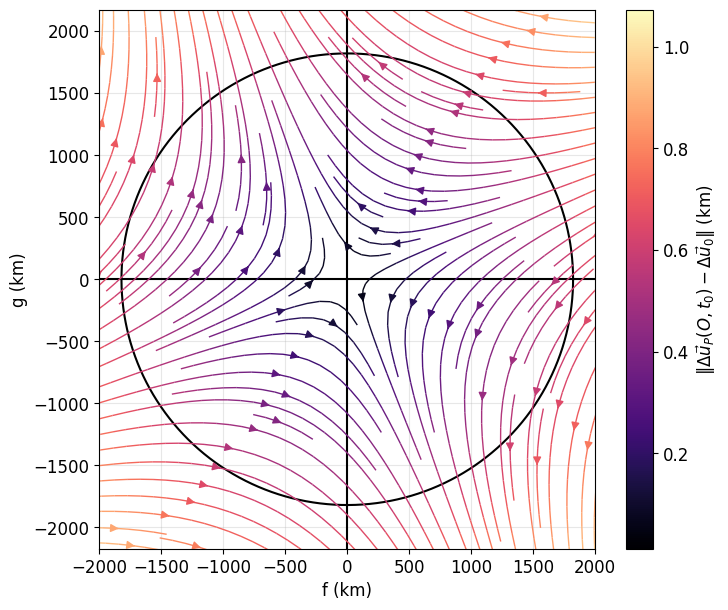

In [22]:
fig, ax = plt.subplots(figsize=(8, 7))

# Plot axis
plt.axhline(0.0, color='black')
plt.axvline(0.0, color='black')

# Plot Io circular shape
ang = np.linspace(0,360,1000)*np.pi/180
plt.plot(io_radius*np.cos(ang),io_radius*np.sin(ang), color='black')

# Plot streamplot of the residual deflection
plt.streamplot(
    xc, yc,
    rf_mean.T, rg_mean.T,
    density=1.5,
    color=magnitude.T,
    linewidth=1.0,
    arrowsize=1.2,
    cmap='magma'
)

plt.colorbar(label=r'$\|\Delta\vec{u}_P(O,t_0)-\Delta\vec{u}_{0}\|$ (km)')

plt.axis('equal')
plt.xlim(-2000,2000)
plt.ylim(-2000,2000)
plt.xlabel('f (km)')
plt.ylabel('g (km)')
plt.grid(alpha=0.3)
plt.savefig('Residual_deflection.png', dpi=300, bbox_inches='tight')
plt.show()

## Figure 5

Keep the selected observer `obs[v]` fixed and evaluate the correction over
time. This observer has the sampled geometric chord closest to the origin at
`occ_time`; the chord need not pass exactly through the center.


In [23]:
# Location of a observer at the center of the tangent plane in Figure 4.
obs_center = obs[v]
print('Central observer: Lon:', obs_center.lon, ', Lat:', obs_center.lat)

Central observer: Lon: -28d25m12s , Lat: 0d04m04.8s


Sample 401 reception epochs at 1 s intervals, from -200 s to +200 s relative to `occ_time`.


In [24]:
times = occ_time + np.linspace(-200,200,401)*u.s

Recompute the light-time-corrected positions of Jupiter, the Sun and Io for this fixed observer at every reception epoch.


In [25]:
spice.furnsh(kernel)
pos_jup, vel_jup = ephem_kernel(times, jup_spkid, obs_center)
pos_sun, vel_sun = ephem_kernel(times, sun_spkid, obs_center)
pos_io, vel_io = ephem_kernel(times, io_spkid, obs_center)
spice.kclear()

Recompute the geometric tangent-plane coordinates along the selected track.
The stellar coordinate remains fixed at its supplied occultation-epoch value
throughout this interval.


In [26]:
DE_io = pos_io.cartesian.norm()   # target

f = DE_io*(pos_star.ra - pos_io.spherical.lon)*np.cos(pos_io.spherical.lat)
g = DE_io*(pos_star.dec - pos_io.spherical.lat)
f = f.to(u.km, equivalencies=u.dimensionless_angles())
g = g.to(u.km, equivalencies=u.dimensionless_angles())

Compute the stellar deflection due to each body for the fixed observer at all sampled epochs.


In [27]:
# Light deflection for the star
vec_rso = - pos_star.cartesian
vec_rao = - pos_jup.cartesian
vec_ras = pos_star.cartesian - pos_jup.cartesian
delta_k_star_jup = delta_kpn(gm=jup_GM, vec_rso=vec_rso, vec_rao=vec_rao, vec_ras=vec_ras)

vec_rso = - pos_star.cartesian
vec_rao = - pos_sun.cartesian
vec_ras = pos_star.cartesian - pos_sun.cartesian
delta_k_star_sun = delta_kpn(gm=sun_GM, vec_rso=vec_rso, vec_rao=vec_rao, vec_ras=vec_ras)


Iterate the finite-distance point-P correction at each epoch, separately for Jupiter and the Sun.


In [28]:
delta_f_jup, delta_g_jup = calc_kP(gm=jup_GM, pos_A=pos_jup, pos_E=pos_io, delta_k_star = delta_k_star_jup, f=f, g=g, delta_f_P=0*u.km, delta_g_P=0*u.km)
delta_f_sun, delta_g_sun = calc_kP(gm=sun_GM, pos_A=pos_sun, pos_E=pos_io, delta_k_star = delta_k_star_sun, f=f, g=g, delta_f_P=0*u.km, delta_g_P=0*u.km)

In [29]:
# Combined tangent-plane correction from Jupiter and the Sun.
delta_f_P = delta_f_jup + delta_f_sun
delta_g_P = delta_g_jup + delta_g_sun

In [30]:
# v now indexes time samples, replacing the earlier observer-grid index.
# For this observer, we compute the index in the array
# where the chord is closest to the tangent plane origin
chord_dist = np.sqrt(f**2+g**2)
v = np.unravel_index(chord_dist.argmin(), chord_dist.shape)

Subtract the **combined Jupiter-plus-Sun correction** at the sampled epoch
of minimum geometric separation:

$$\vec\epsilon_t(t)=\Delta\vec u_P(O_{\rm ref},t)
-\Delta\vec u_P(O_{\rm ref},t_{\rm ref}).$$

Here `v` has been recomputed as a time-array index, and
$t_{\rm ref}=\mathrm{times}[v]$. It is not forced to equal `occ_time`, and the
minimum geometric separation is not forced to be zero.

The dashed lines in the plot mark the first and last sampled epochs inside
Io's geometric circular limb; they are not interpolated contact times. The
horizontal line at 1.187 km is a fixed reference value for comparison with
the temporal estimate; it is not recalculated in this notebook. The plotted
quantity is the norm of the correction residual $\|\vec\epsilon_t\|$; the
existing y-axis label omits the correction symbol $\Delta$. The figure is
saved as `Residual_deflection_time.png`.


In [31]:
resid_f = delta_f_P - delta_f_P[v]
resid_g = delta_g_P - delta_g_P[v]

In [32]:
# This command identifies the indexes in the array where the chord is within Io radius
k = np.where(np.sqrt(f**2 + g**2) < io_radius)

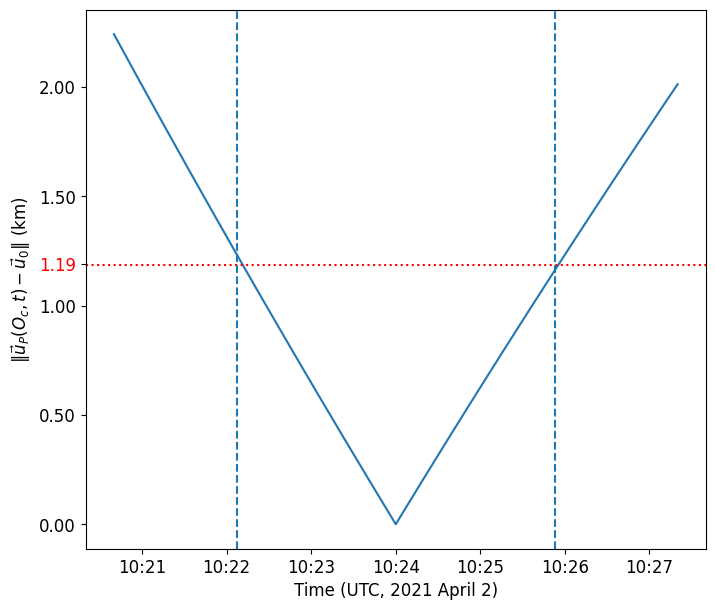

In [33]:
import matplotlib.dates as mdates
fig, ax = plt.subplots(figsize=(8, 7))

# Plots total residual over time
plt.plot(times.datetime, np.sqrt(resid_f**2 + resid_g**2))

# Plots vertical lines where the chord crosses the Io limb
plt.axvline(times[k].min().datetime, linestyle='--')
plt.axvline(times[k].max().datetime, linestyle='--')

# Plots a dot line where the residuals is equal to the estimated parameter
plt.axhline(1.187, color='red', linestyle=':')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ticks = ax.set_yticks([0, 0.5, 1.0, 1.19, 1.5, 2.0])
ticks[3].label1.set_color("red")

plt.xlabel('Time (UTC, 2021 April 2)')
plt.ylabel(r'$\|\vec{u}_P(O_c,t) - \vec{u}_0\|$ (km)')
plt.savefig('Residual_deflection_time.png', dpi=300, bbox_inches='tight')